<a href="https://colab.research.google.com/github/NeuroNex-ModelX/drainage-failure-sri-lanka/blob/main/08_trend.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08 · Trend: is drainage getting worse?
**Owner:** Sayuni · **Needs:** 05 · **Makes:** `outputs/trend_ds.csv`, `outputs/trend_district.csv`, `outputs/trend_national.csv`

Proposal Step 5: for each division, floods per heavy-rain day in **2005–2014** vs **2015–(last year of
flood records)**. If the records end before 2019, the available years are split into two equal halves. If floods now happen more often for the same amount of heavy rain, drainage is degrading.
Significance: exact test comparing the two rates (binomial test conditional on the total number of floods).

In [2]:
# --- SETUP ---
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ['MODELX_BASE'] = '/content/drive/MyDrive/ModelX'
sys.path.append(os.path.join(os.environ.get('MODELX_BASE', '..'), 'src'))
from common import *
from scipy.stats import binomtest, wilcoxon
import matplotlib.pyplot as plt

t = pd.read_csv(os.path.join(PROC, 'analysis_table.csv'))
t = t[t['label_known'] == 1]
LAST = int(t['year'].max())
if LAST >= 2019:
    P1, P2 = (2005, 2014), (2015, LAST)          # proposal periods
else:
    # flood records stop early (e.g. HDX table ends in 2013): split the available years into two equal halves
    n = (LAST - 1995 + 1) // 2
    P1, P2 = (LAST - 2 * n + 1, LAST - n), (LAST - n + 1, LAST)
HEAVY = 'days_over_50'       # a 'heavy-rain day' = more than 50 mm in a day
print('Periods:', P1, 'vs', P2)

Mounted at /content/drive
Periods: (1995, 2004) vs (2005, 2014)


In [3]:
def period_sums(a, b):
    s = t[t['year'].between(a, b)].groupby('pcode').agg(floods=('flood', 'sum'), heavy_days=(HEAVY, 'sum'))
    return s


s1, s2 = period_sums(*P1), period_sums(*P2)
tr = s1.join(s2, lsuffix='_p1', rsuffix='_p2', how='outer').fillna(0)
tr['rate_p1'] = 100 * tr['floods_p1'] / tr['heavy_days_p1'].replace(0, np.nan)   # floods per 100 heavy-rain days
tr['rate_p2'] = 100 * tr['floods_p2'] / tr['heavy_days_p2'].replace(0, np.nan)
tr['change'] = tr['rate_p2'] - tr['rate_p1']


def test_row(r):
    k1, k2, n1, n2 = r['floods_p1'], r['floods_p2'], r['heavy_days_p1'], r['heavy_days_p2']
    if n1 == 0 or n2 == 0 or (k1 + k2) < 3:
        return np.nan
    return binomtest(int(k2), int(k1 + k2), n2 / (n1 + n2)).pvalue


tr['p_value'] = tr.apply(test_row, axis=1)
tr['trend'] = np.select(
    [tr['p_value'].isna(), (tr['p_value'] < 0.10) & (tr['change'] > 0), (tr['p_value'] < 0.10) & (tr['change'] < 0)],
    ['Not enough data', 'Worsening', 'Improving'], default='No clear change')
tr = tr.reset_index().merge(load_ds_list()[['pcode', 'ds_name', 'district_name']], on='pcode')
tr.to_csv(os.path.join(OUT, 'trend_ds.csv'), index=False)
save_meta('trend_periods', f'{P1[0]}-{P1[1]} vs {P2[0]}-{P2[1]}')
print(tr['trend'].value_counts())

trend
No clear change    180
Not enough data    119
Worsening           38
Improving            2
Name: count, dtype: int64


In [4]:
# Island-wide: did the rate go up across divisions? (paired Wilcoxon test)
ok = tr.dropna(subset=['rate_p1', 'rate_p2'])
if len(ok) > 10:
    w = wilcoxon(ok['rate_p2'], ok['rate_p1'])
    up, down = (ok['change'] > 0).sum(), (ok['change'] < 0).sum()
    print(f"Divisions with a higher rate in period 2: {up} | lower: {down} | unchanged: {len(ok) - up - down}")
    print(f"Median change: {ok['change'].median():.2f}, mean change: {ok['change'].mean():.2f} floods per 100 "
          f"heavy-rain days; Wilcoxon p = {w.pvalue:.3g}")
    print('(The median is 0 because most divisions had no floods in either period; the test looks at the ones that changed.)')

# Whole island, two periods: one exact test on the totals
k1, k2 = s1['floods'].sum(), s2['floods'].sum()
n1, n2 = s1['heavy_days'].sum(), s2['heavy_days'].sum()
p_nat = binomtest(int(k2), int(k1 + k2), n2 / (n1 + n2)).pvalue
print(f"Island-wide: {100 * k1 / n1:.2f} -> {100 * k2 / n2:.2f} flooded division-months per 100 heavy-rain days "
      f"(p = {p_nat:.3g})")
save_meta('trend_island', f'{100 * k1 / n1:.2f} -> {100 * k2 / n2:.2f} per 100 heavy-rain days, p={p_nat:.3g}')

Divisions with a higher rate in period 2: 217 | lower: 52 | unchanged: 70
Median change: 3.08, mean change: 6.99 floods per 100 heavy-rain days; Wilcoxon p = 1.55e-25
(The median is 0 because most divisions had no floods in either period; the test looks at the ones that changed.)
Island-wide: 4.31 -> 8.01 flooded division-months per 100 heavy-rain days (p = 2.09e-38)


{'boundaries': 'Survey Dept of Sri Lanka via OCHA/HDX (cod-ab-lka), CC BY-IGO',
 '_updated': '2026-11-03 07:42',
 'flood_records': 'DesInventar Sri Lanka, 1974-2014',
 'flood_last_year': 2014,
 'rainfall': 'CHIRPS v2.0 daily 0.05 deg, 1995-2025 (UCSB CHC)',
 'elevation': 'Open-Meteo elevation API (Copernicus DEM GLO-90), ~1 km sample grid',
 'tree_loss': 'Global Forest Watch / Hansen et al., tree cover loss 2001-2025, by DS division',
 'drains': 'OpenStreetMap waterways (Geofabrik extract), ODbL',
 'census': 'Census of Population and Housing 2024 (DCS): population (GN table summed to DS), households, piped water (A14), in-house toilet (A16), clean cooking fuel (A13)',
 'model_A': 'Random forest; test 2010-2014',
 'dfs_period': '1995-2014',
 'trend_periods': '1995-2004 vs 2005-2014',
 'trend_island': '4.31 -> 8.01 per 100 heavy-rain days, p=2.09e-38'}

### District level
Most single divisions have too few floods for a test of their own ('Not enough data').
Adding up the divisions of each district gives enough floods to test the trend in all 25 districts.

In [5]:
dist = load_ds_list()[['pcode', 'district_name']]
def district_sums(a, b):
    x = t[t['year'].between(a, b)].merge(dist, on='pcode')
    return x.groupby('district_name').agg(floods=('flood', 'sum'), heavy_days=(HEAVY, 'sum'))
td = district_sums(*P1).join(district_sums(*P2), lsuffix='_p1', rsuffix='_p2', how='outer').fillna(0)
td['rate_p1'] = 100 * td['floods_p1'] / td['heavy_days_p1'].replace(0, np.nan)
td['rate_p2'] = 100 * td['floods_p2'] / td['heavy_days_p2'].replace(0, np.nan)
td['change'] = td['rate_p2'] - td['rate_p1']
td['p_value'] = td.apply(test_row, axis=1)
td['trend'] = np.select(
    [td['p_value'].isna(), (td['p_value'] < 0.10) & (td['change'] > 0), (td['p_value'] < 0.10) & (td['change'] < 0)],
    ['Not enough data', 'Worsening', 'Improving'], default='No clear change')
td = td.reset_index()
td.to_csv(os.path.join(OUT, 'trend_district.csv'), index=False)
print(td['trend'].value_counts())
td.sort_values('change', ascending=False).round(3)

trend
Worsening          17
No clear change     7
Improving           1
Name: count, dtype: int64


,district_name,floods_p1,heavy_days_p1,floods_p2,heavy_days_p2,rate_p1,rate_p2,change,p_value,trend
14,Mannar,1,81,22,98,1.235,22.449,21.214,0.000,Worsening
21,Puttalam,51,140,76,151,36.429,50.331,13.903,0.076,Worsening
13,Kurunegala,28,364,98,531,7.692,18.456,10.763,0.000,Worsening
8,Jaffna,12,578,83,672,2.076,12.351,10.275,0.000,Worsening
7,Hambantota,19,304,30,187,6.250,16.043,9.793,0.001,Worsening
6,Gampaha,46,387,101,467,11.886,21.627,9.741,0.001,Worsening
17,Monaragala,4,345,31,321,1.159,9.657,8.498,0.000,Worsening
4,Colombo,32,631,85,659,5.071,12.898,7.827,0.000,Worsening
9,Kalutara,56,1266,133,1319,4.423,10.083,5.660,0.000,Worsening
22,Ratnapura,86,1276,132,1090,6.740,12.110,5.370,0.000,Worsening


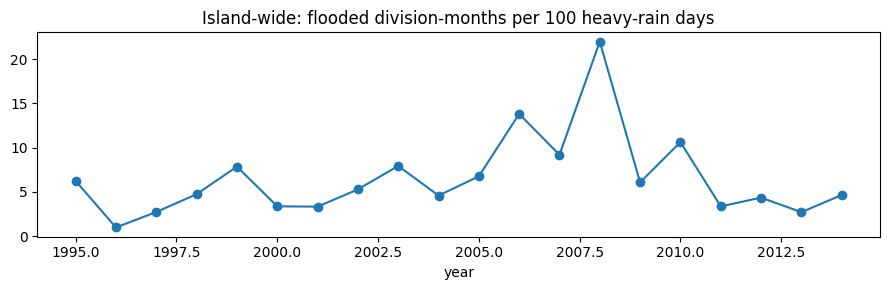

,ds_name,district_name,rate_p1,rate_p2,p_value,trend
122,Hambantota,Hambantota,33.333333,200.000000,0.005111,Worsening
215,Nikaweratiya,Kurunegala,0.000000,77.777778,0.016767,Worsening
244,Mundel,Puttalam,33.333333,100.000000,0.257080,No clear change
123,Ambalantota,Hambantota,20.000000,83.333333,0.047560,Worsening
243,Puttalam,Puttalam,66.666667,128.571429,0.405227,No clear change
130,Tangalle,Hambantota,12.500000,63.636364,0.036920,Worsening
308,Thanamalwila,Monaragala,9.090909,57.142857,0.078781,Worsening
248,Arachchikattuwa,Puttalam,22.222222,66.666667,0.225856,No clear change
214,Rasnayakapura,Kurunegala,55.555556,100.000000,0.423950,No clear change
234,Udubaddawa,Kurunegala,5.882353,46.153846,0.047896,Worsening


In [6]:
# National series: floods per 100 heavy-rain days, by year (figure for the report)
nat = t.groupby('year').agg(floods=('flood', 'sum'), heavy_days=(HEAVY, 'sum'))
nat['floods_per_100_heavy_days'] = 100 * nat['floods'] / nat['heavy_days']
nat.reset_index().to_csv(os.path.join(OUT, 'trend_national.csv'), index=False)
nat['floods_per_100_heavy_days'].plot(marker='o', figsize=(9, 3),
                                      title='Island-wide: flooded division-months per 100 heavy-rain days')
plt.tight_layout(); plt.show()

tr.sort_values('change', ascending=False).head(10)[['ds_name', 'district_name', 'rate_p1', 'rate_p2', 'p_value', 'trend']]